<a href="https://colab.research.google.com/github/atempvisit/learning-machine-learning/blob/main/Module_23_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline

In [2]:
df = load_breast_cancer(as_frame=True).frame

df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.2560,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.4630,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.0750,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.5950,5.772,86.22,0.006522,0.06158,0.07117,0.01664,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [3]:
df.shape

(569, 31)

In [5]:
X = df.drop('target', axis=1)
y = df['target']

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [10]:
np.set_printoptions(suppress=True, precision=4)

pca_full = PCA(n_components=None)

X_pca_full = pca_full.fit_transform(X_scaled)

explained = pca_full.explained_variance_ratio_

explained

array([0.4427, 0.1897, 0.0939, 0.066 , 0.055 , 0.0402, 0.0225, 0.0159,
       0.0139, 0.0117, 0.0098, 0.0087, 0.008 , 0.0052, 0.0031, 0.0027,
       0.002 , 0.0018, 0.0016, 0.001 , 0.001 , 0.0009, 0.0008, 0.0006,
       0.0005, 0.0003, 0.0002, 0.0001, 0.    , 0.    ])

In [11]:
cum_variance = np.cumsum(explained)

cum_variance

array([0.4427, 0.6324, 0.7264, 0.7924, 0.8473, 0.8876, 0.9101, 0.926 ,
       0.9399, 0.9516, 0.9614, 0.9701, 0.9781, 0.9834, 0.9865, 0.9892,
       0.9911, 0.9929, 0.9945, 0.9956, 0.9966, 0.9975, 0.9983, 0.9989,
       0.9994, 0.9997, 0.9999, 1.    , 1.    , 1.    ])

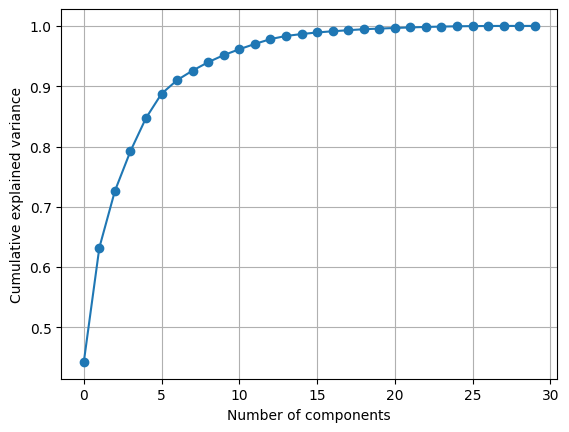

In [12]:
plt.plot(cum_variance, marker='o')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.grid(True)
plt.show()

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)

# Pipeline without PCA: Scale -> Logistic Regression

pipe_no_pca = Pipeline([
    ("scaler", StandardScaler()),
    ('clf', LogisticRegression(max_iter=500))
])

pipe_no_pca.fit(X_train, y_train)

pred_no_pca = pipe_no_pca.predict(X_test)

accuracy_no_pca = accuracy_score(y_test, pred_no_pca)

In [16]:
print(f"Accuracy without PCA: {accuracy_no_pca * 100:.2f}%")

Accuracy without PCA: 98.25%


In [26]:
pipeline_with_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=10)),
    ('clf', LogisticRegression(max_iter=500))
])

pipeline_with_pca.fit(X_train, y_train)

pred_with_pca = pipeline_with_pca.predict(X_test)

accuracy_with_pca = accuracy_score(y_test, pred_with_pca)

In [27]:
print(f"Accuracy with PCA: {accuracy_with_pca * 100:.2f}%")

Accuracy with PCA: 97.37%


# Explanation of the Results

If PCA accuracy is similar:

- Great. We reduced dimensions without losing performance.

If PCA accuracy is better:

- PCA likely removed redundancy/noise that was confusing the model.

If PCA accuracy is worse:

- We removed useful information.
- Increase the threshold (for example, 0.98), or skip PCA.

Bottom line: PCA is a tool. Use it when it matches the problem conditions.